In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/System-Threat-Forecaster/sample_submission.csv
/kaggle/input/System-Threat-Forecaster/train.csv
/kaggle/input/System-Threat-Forecaster/test.csv


# Description

This project aims to predict the likelihood of a system being infected by malware using telemetry data collected by antivirus software. Each system is identified by a unique MachineID, with various system properties as features

# Importing Required Packages

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import PCA
from sklearn.model_selection import RandomizedSearchCV
from sklearn.preprocessing import OrdinalEncoder
from sklearn.feature_selection import RFE
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

# Loading Train and Test Dataset

In [3]:
data=pd.read_csv('/kaggle/input/System-Threat-Forecaster/train.csv')

In [4]:
test_data=pd.read_csv("/kaggle/input/System-Threat-Forecaster/test.csv")

# EDA

In [5]:
data.tail()

,MachineID,ProductName,EngineVersion,AppVersion,SignatureVersion,IsBetaUser,RealTimeProtectionState,IsPassiveModeEnabled,AntivirusConfigID,NumAntivirusProductsInstalled,...,IsSecureBootEnabled,IsVirtualDevice,IsTouchEnabled,IsPenCapable,IsAlwaysOnAlwaysConnectedCapable,IsGamer,RegionIdentifier,DateAS,DateOS,target
99995,a378b2196a7a1d8ee0d4f989ee46730e,win8defender,1.1.15200.1,4.18.1807.18075,1.275.1582.0,0,7.0,0,68585.0,2.0,...,0,0.0,0,0,0.0,1.0,7.0,2018-09-21 00:59:00,2018-09-20,0
99996,7f4433ca05d24b9bbdd3932f8b05e61f,win8defender,1.1.15100.1,4.18.1806.18062,1.273.1156.0,0,7.0,0,11280.0,2.0,...,0,0.0,0,0,0.0,0.0,3.0,2018-08-10 07:23:00,2018-07-10,0
99997,d6852dfff534e03d5ddfd3c7875ab072,win8defender,1.1.15200.1,4.18.1807.18075,1.275.209.0,0,7.0,0,53447.0,1.0,...,1,0.0,0,0,0.0,1.0,1.0,2018-08-26 23:51:00,2018-03-13,1
99998,70a8dc682128c9ff78a3de5aea9dac74,win8defender,1.1.14901.4,4.16.17656.18052,1.269.641.0,0,7.0,0,53447.0,1.0,...,1,0.0,1,1,1.0,0.0,1.0,2018-06-04 17:13:00,2018-05-08,0
99999,ad9c385b53f2ca788933a39603b84eda,win8defender,1.1.15000.2,4.18.1806.18062,1.271.1003.0,0,7.0,0,7945.0,2.0,...,1,0.0,0,0,0.0,1.0,11.0,2018-07-14 15:36:00,2018-08-14,0


In [6]:
data.shape

(100000, 76)

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 76 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   MachineID                           100000 non-null  object 
 1   ProductName                         100000 non-null  object 
 2   EngineVersion                       100000 non-null  object 
 3   AppVersion                          100000 non-null  object 
 4   SignatureVersion                    100000 non-null  object 
 5   IsBetaUser                          100000 non-null  int64  
 6   RealTimeProtectionState             99934 non-null   float64
 7   IsPassiveModeEnabled                100000 non-null  int64  
 8   AntivirusConfigID                   99924 non-null   float64
 9   NumAntivirusProductsInstalled       99924 non-null   float64
 10  NumAntivirusProductsEnabled         99924 non-null   float64
 11  HasTpm                     

In [8]:
test_data.head()

,MachineID,ProductName,EngineVersion,AppVersion,SignatureVersion,IsBetaUser,RealTimeProtectionState,IsPassiveModeEnabled,AntivirusConfigID,NumAntivirusProductsInstalled,...,FirmwareVersionID,IsSecureBootEnabled,IsVirtualDevice,IsTouchEnabled,IsPenCapable,IsAlwaysOnAlwaysConnectedCapable,IsGamer,RegionIdentifier,DateAS,DateOS
0,c2c61173092ad20db5585ca8c10de6e0,win8defender,1.1.15100.1,4.18.1807.18075,1.273.1276.0,0,7.0,0,53447.0,1.0,...,48751.0,0,0.0,0,0,0.0,1.0,11.0,2018-08-12 13:12:00,2018-07-10
1,2e6bb5362ba1ce897feeb1de5edea686,win8defender,1.1.15100.1,4.10.209.0,1.273.371.0,0,7.0,0,46184.0,2.0,...,64709.0,1,0.0,0,0,0.0,0.0,12.0,2018-07-26 06:54:00,2016-10-11
2,692649baed1c50bb8d051ae7f06e3625,win8defender,1.1.15200.1,4.18.1807.18075,1.275.263.0,0,7.0,0,51954.0,2.0,...,33094.0,1,0.0,0,0,0.0,0.0,10.0,2018-08-27 17:29:00,2018-05-08
3,2ff95e7d97e9f80ec81c97622dd93ed6,win8defender,1.1.15300.6,4.18.1807.18075,1.277.58.0,0,7.0,0,41571.0,2.0,...,26184.0,1,0.0,0,0,0.0,0.0,10.0,2018-09-25 22:13:00,2018-05-08
4,256766b4c5011e146f05b323863e08a4,win8defender,1.1.14800.3,4.14.17639.18041,1.267.898.0,0,7.0,0,40645.0,3.0,...,12126.0,0,0.0,0,0,0.0,0.0,7.0,2018-05-06 01:31:00,2018-06-12


In [9]:
test_data.shape

(10000, 75)

**Descritive Statistics of Numerical Features**

In [10]:
data.describe()

,IsBetaUser,RealTimeProtectionState,IsPassiveModeEnabled,AntivirusConfigID,NumAntivirusProductsInstalled,NumAntivirusProductsEnabled,HasTpm,CountryID,CityID,GeoRegionID,...,FirmwareManufacturerID,FirmwareVersionID,IsSecureBootEnabled,IsVirtualDevice,IsTouchEnabled,IsPenCapable,IsAlwaysOnAlwaysConnectedCapable,IsGamer,RegionIdentifier,target
count,100000.0,99934.000000,100000.000000,99924.000000,99924.000000,99924.000000,100000.000000,100000.000000,99377.000000,100000.000000,...,99624.000000,99666.000000,100000.000000,99980.000000,100000.000000,100000.000000,99866.000000,99441.000000,99441.000000,100000.000000
mean,0.0,6.848430,0.017620,47975.710440,1.326528,1.018264,0.996780,108.078790,81029.938587,169.741630,...,401.987613,32942.648044,0.495690,0.003841,0.128470,0.040580,0.058398,0.296668,7.875866,0.505250
std,0.0,1.015166,0.131566,13803.321533,0.520681,0.155291,0.056654,63.062151,48944.027074,89.188929,...,221.318891,21151.970827,0.499984,0.061855,0.334614,0.197316,0.234496,0.456791,4.562533,0.499975
min,0.0,0.000000,0.000000,39.000000,1.000000,0.000000,0.000000,1.000000,7.000000,1.000000,...,2.000000,121.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,0.0,7.000000,0.000000,49480.000000,1.000000,1.000000,1.000000,51.000000,36694.000000,89.000000,...,142.000000,13020.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,0.000000
50%,0.0,7.000000,0.000000,53447.000000,1.000000,1.000000,1.000000,97.000000,82373.000000,181.000000,...,500.000000,33066.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,10.000000,1.000000
75%,0.0,7.000000,0.000000,53447.000000,2.000000,1.000000,1.000000,162.000000,122835.000000,267.000000,...,556.000000,52357.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,11.000000,1.000000
max,0.0,8.000000,1.000000,70490.000000,5.000000,4.000000,1.000000,222.000000,167957.000000,296.000000,...,1083.000000,72091.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,15.000000,1.000000


**Descriptive Statistics of Categorical Features**

In [11]:
data = data.drop(columns=['MachineID'], errors='ignore')

categorical_features = data.select_dtypes(include=['object', 'category']).columns

data[categorical_features].describe(include='all')

,ProductName,EngineVersion,AppVersion,SignatureVersion,PlatformType,Processor,OSVersion,OsPlatformSubRelease,OSBuildLab,SKUEditionName,...,OSBranch,OSEdition,OSSkuFriendlyName,OSInstallType,AutoUpdateOptionsName,OSGenuineState,LicenseActivationChannel,FlightRing,DateAS,DateOS
count,100000,100000,100000,100000,100000,100000,100000,100000,100000,100000,...,100000,100000,100000,100000,100000,100000,100000,100000,100000,99976
unique,2,37,69,2735,4,3,7,9,281,8,...,13,20,18,9,6,4,6,7,2695,112
top,win8defender,1.1.15200.1,4.18.1807.18075,1.273.1420.0,windows10,x64,10.0.0.0,rs4,17134.1.amd64fre.rs4_release.180410-1804,Home,...,rs4_release,Core,CORE,UUPUpgrade,FullAuto,IS_GENUINE,Retail,Retail,2018-08-15 06:29:00,2018-08-14
freq,99771,45219,62119,1274,98344,91262,98368,45837,42964,62863,...,46909,39275,39273,32033,45154,89860,52195,94153,1274,20905


**Count Plots for Categorical Features with less than 5 Unique Values**

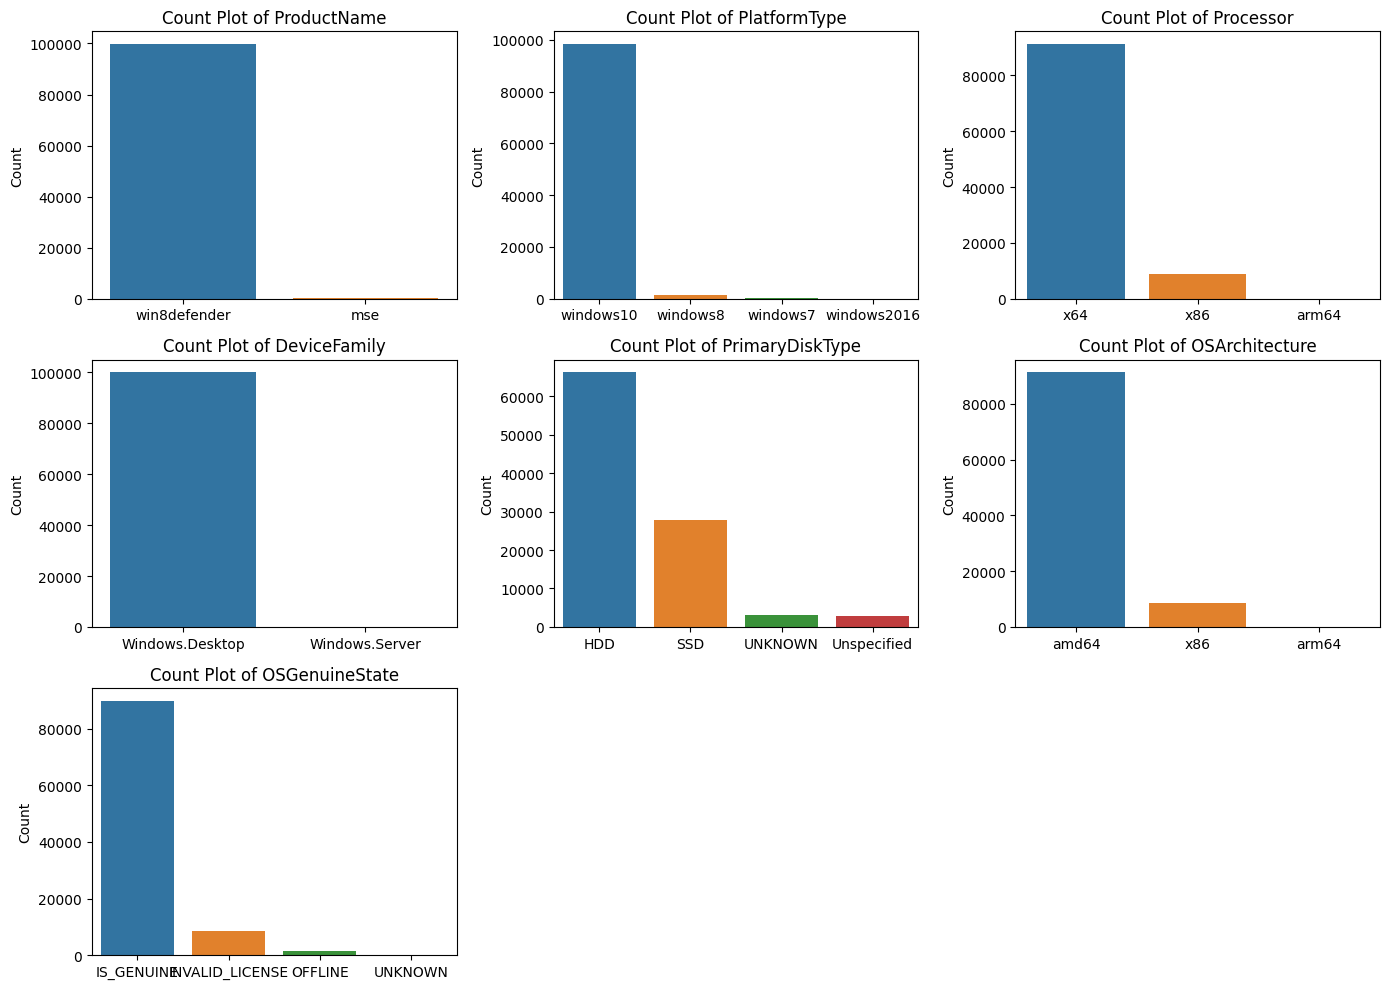

In [12]:
categorical_features = data.select_dtypes(include=["object", "category"]).columns
filtered_features = [feature for feature in categorical_features if data[feature].nunique() <= 5][:7]

plt.figure(figsize=(14, 10))
for i, feature in enumerate(filtered_features, 1):
    plt.subplot(3, 3, i)
    sns.countplot(x=feature, data=data, order=data[feature].value_counts().index)
    plt.title(f'Count Plot of {feature}')
    plt.xlabel('')
    plt.ylabel('Count')

plt.tight_layout()
plt.show()


The count plots provide an overview of the distribution of categorical features in the dataset.

* ProductName: Win8Defender dominates with most systems using it, while MSE has minimal presence.
* Platform: Windows10 is the most common platform, followed by Windows8.
* Processor: Majority of systems use x64 processors, with very few using x86.
* DeviceFamily: Windows.Desktop is the predominant device family.
* PrimaryDiskType: HDD is the most common disk type, followed by SSD, with a notable number of unknown and unspecified entries.
* OsArchitecture: AMD64 is the most used architecture, while x86 have minimal presence.

**Correlation Heatmap**

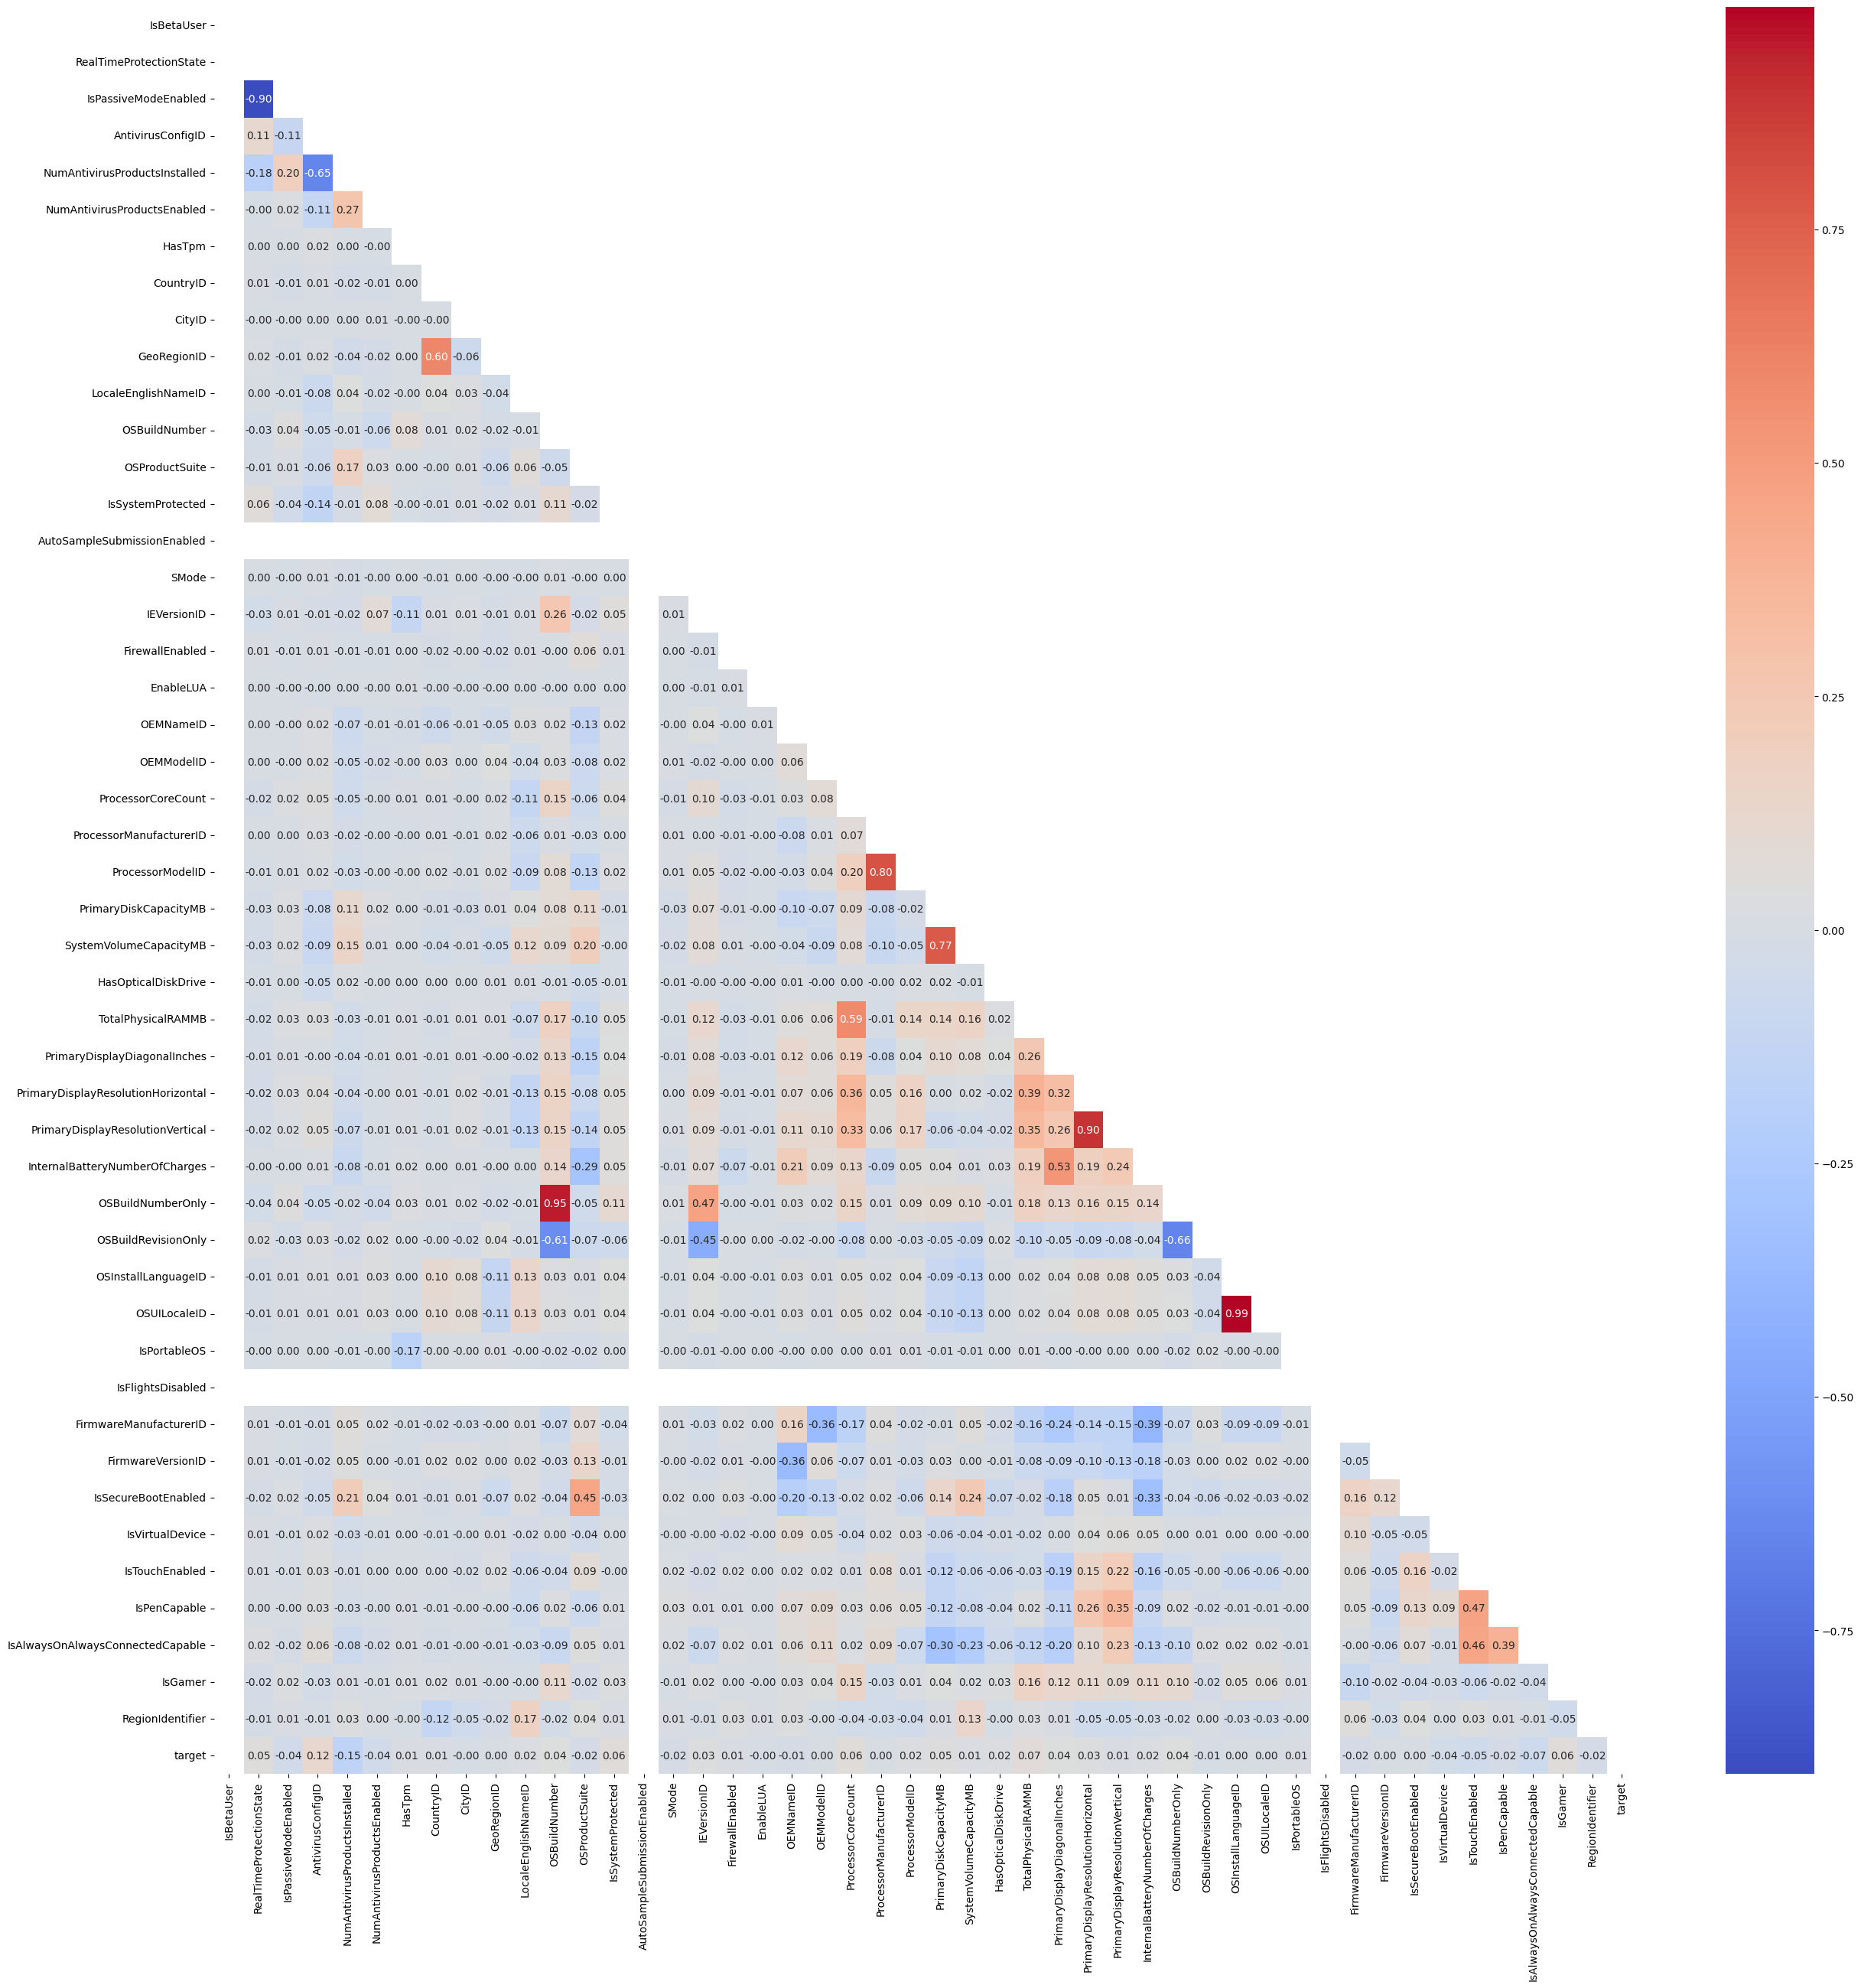

In [13]:
plt.figure(figsize=(30, 30))
data_dropped = data.dropna()
corr_matrix = data_dropped.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, mask=mask, fmt=".2f", cmap="coolwarm")
plt.show()

The heatmap shows correlations between numerical features. Most features have low correlation, while a few exhibit moderate to high correlation.

**Correlation of Numerical Features with Target**

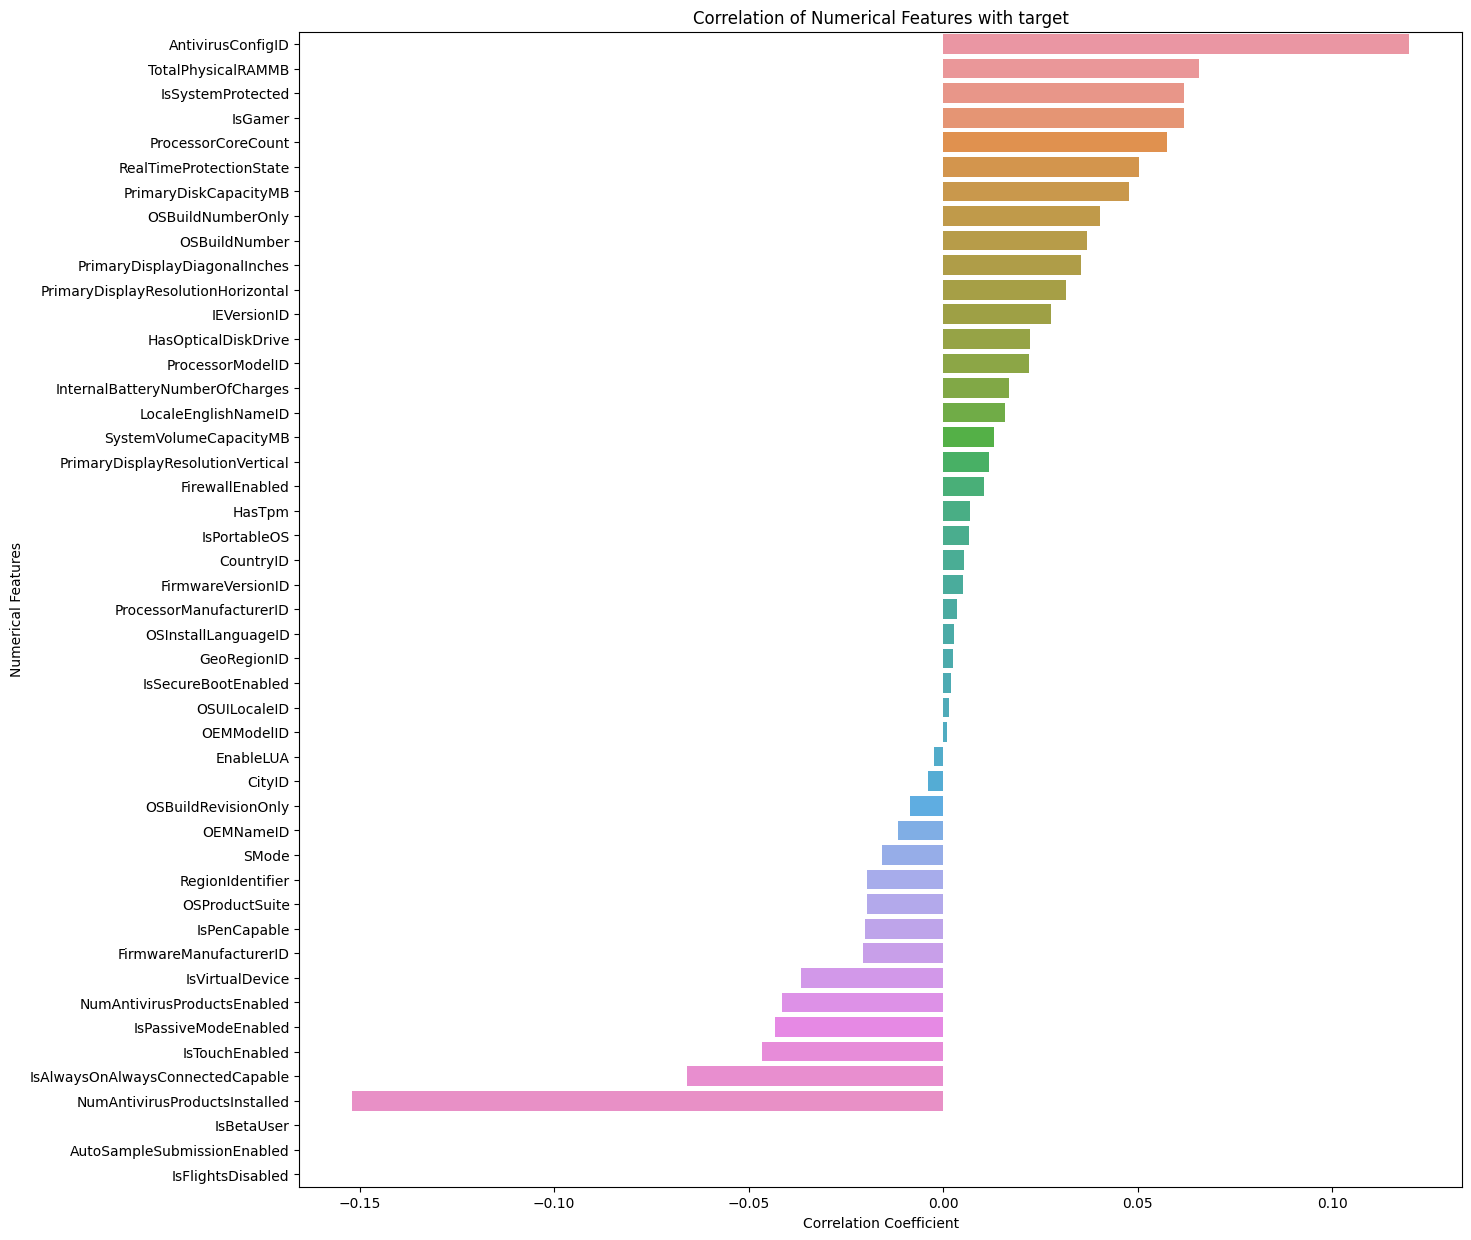

In [14]:
numerical_features = data.select_dtypes(include=["int64", "float64"]).columns.tolist()
numerical_features.remove('target')

data_dropped = data[numerical_features].dropna()

correlations = data_dropped.corrwith(data.loc[data_dropped.index, 'target']).sort_values(ascending=False)

plt.figure(figsize=(15,15))
sns.barplot(x=correlations.values, y=correlations.index)
plt.title('Correlation of Numerical Features with target')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Numerical Features')
plt.show()

The plot shows that AntivirusConfigID, TotalPhysicalRAMMB, IsSystemProtected, and IsGamer have a positive correlation with the target, while IsAlwaysOnAlwaysConnectedCable, IsTouchEnabled, and IsPassiveModeEnabled have a negative correlation.

**Histograms of Top 7 Correlated Numerical Features**

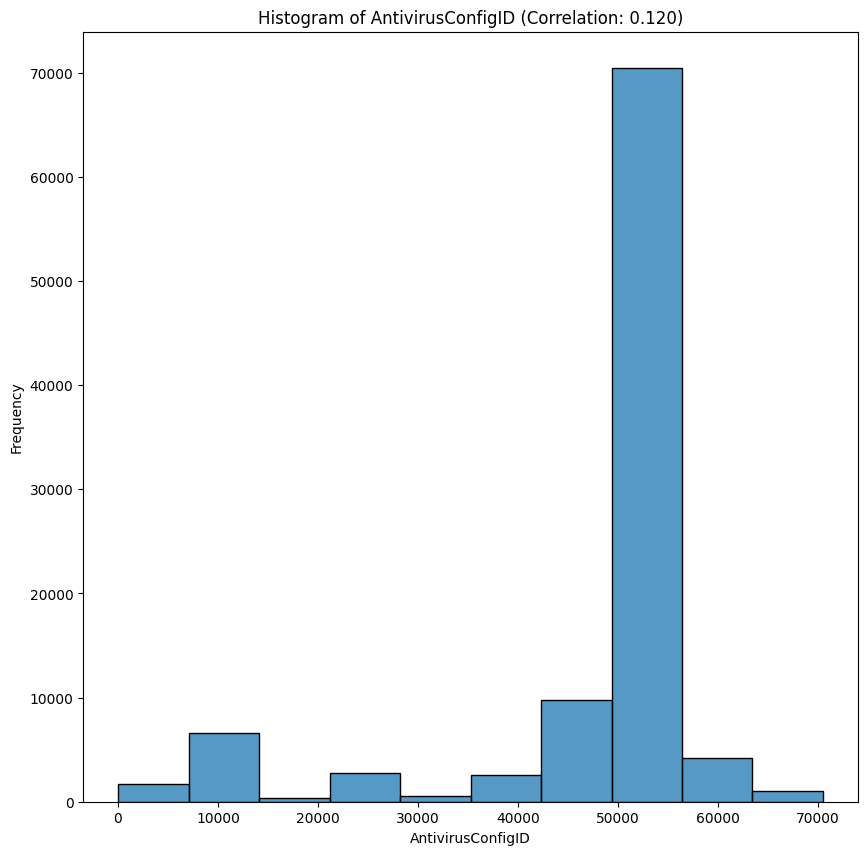

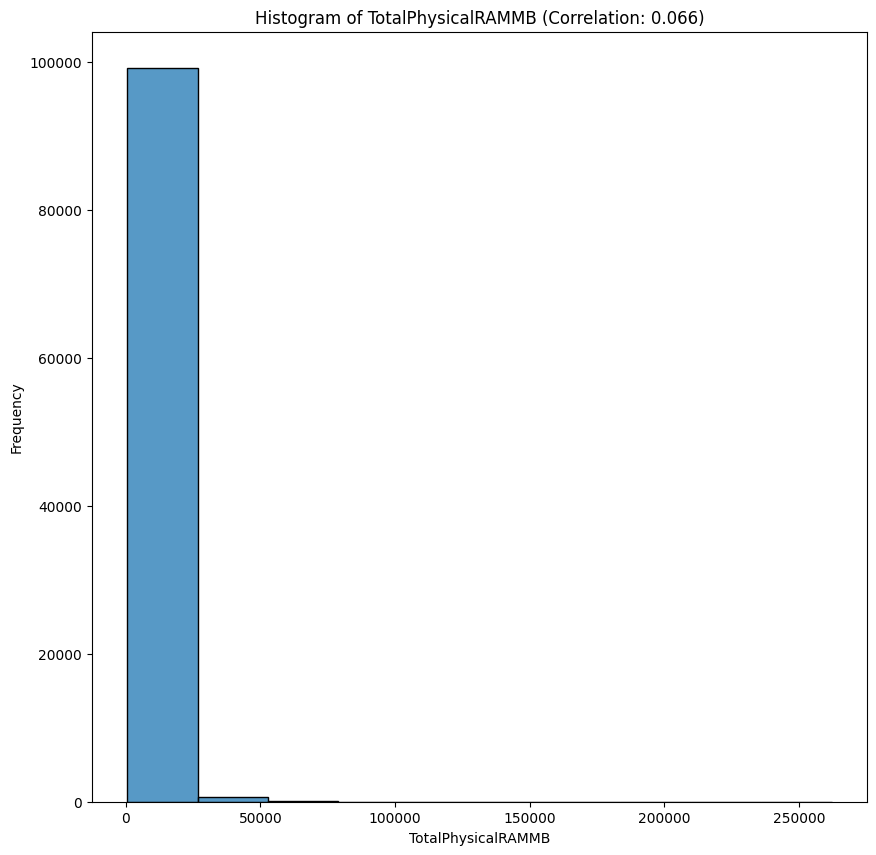

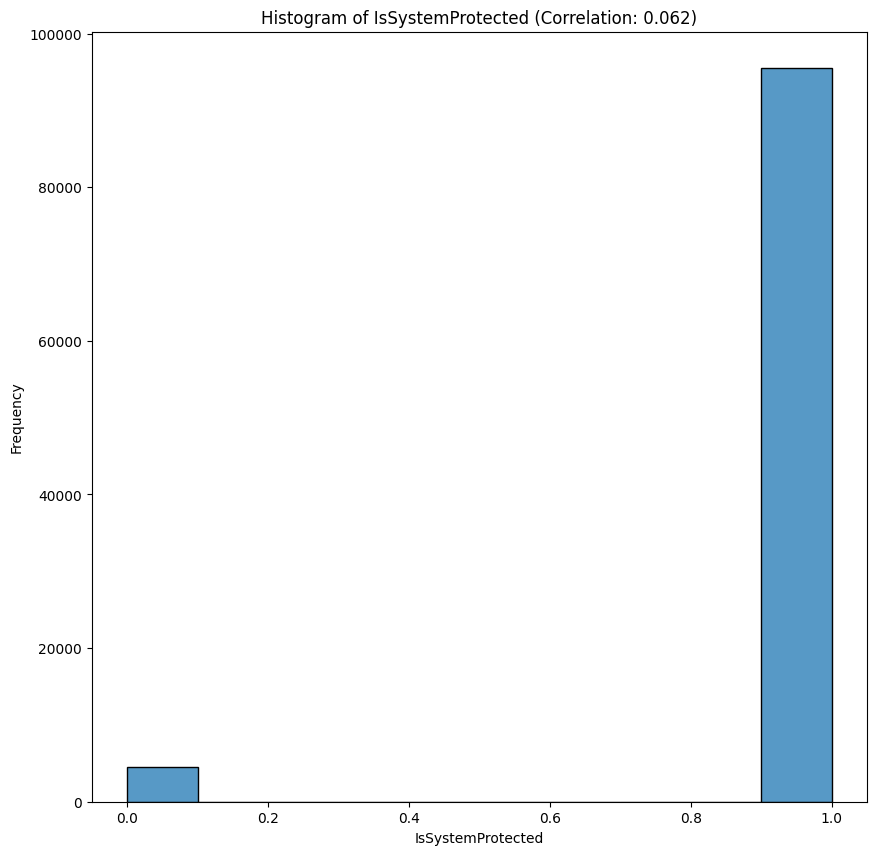

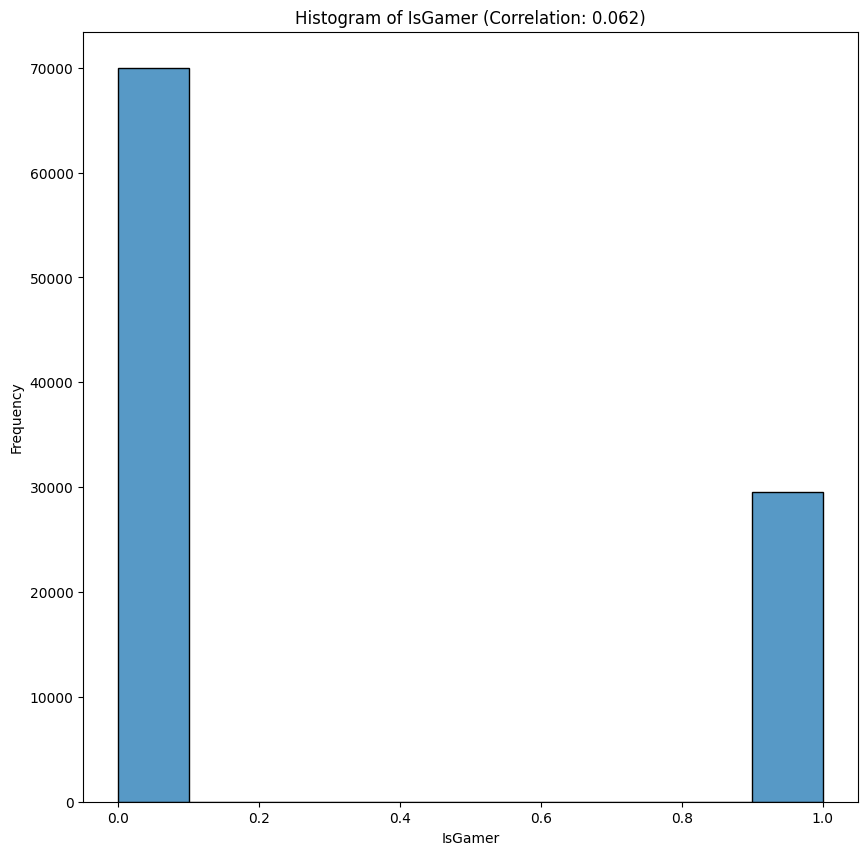

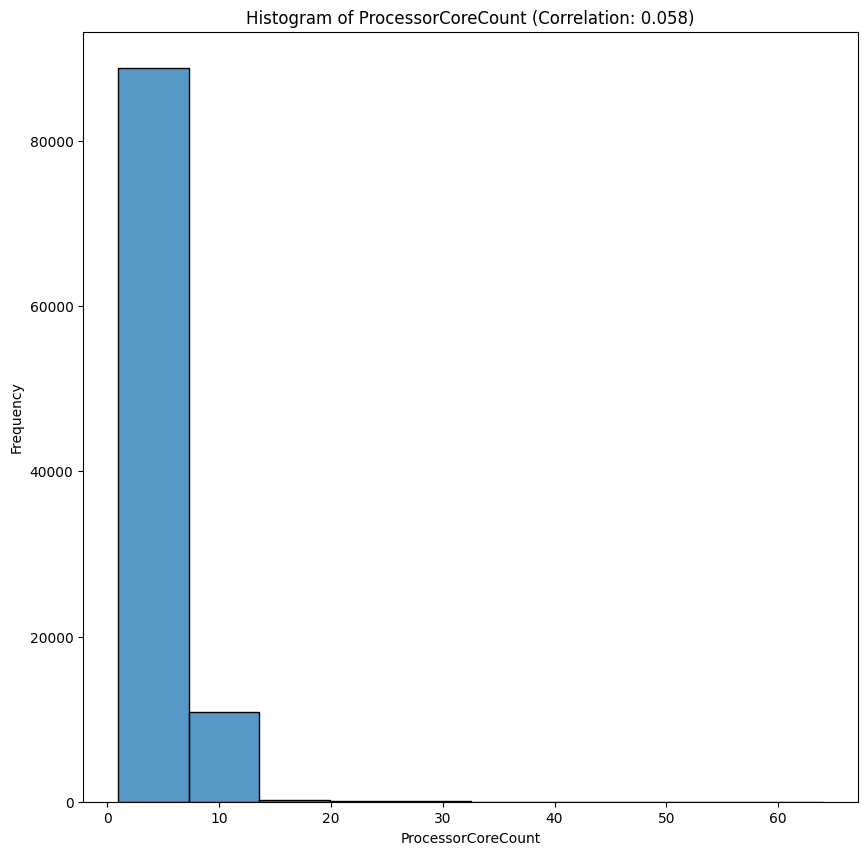

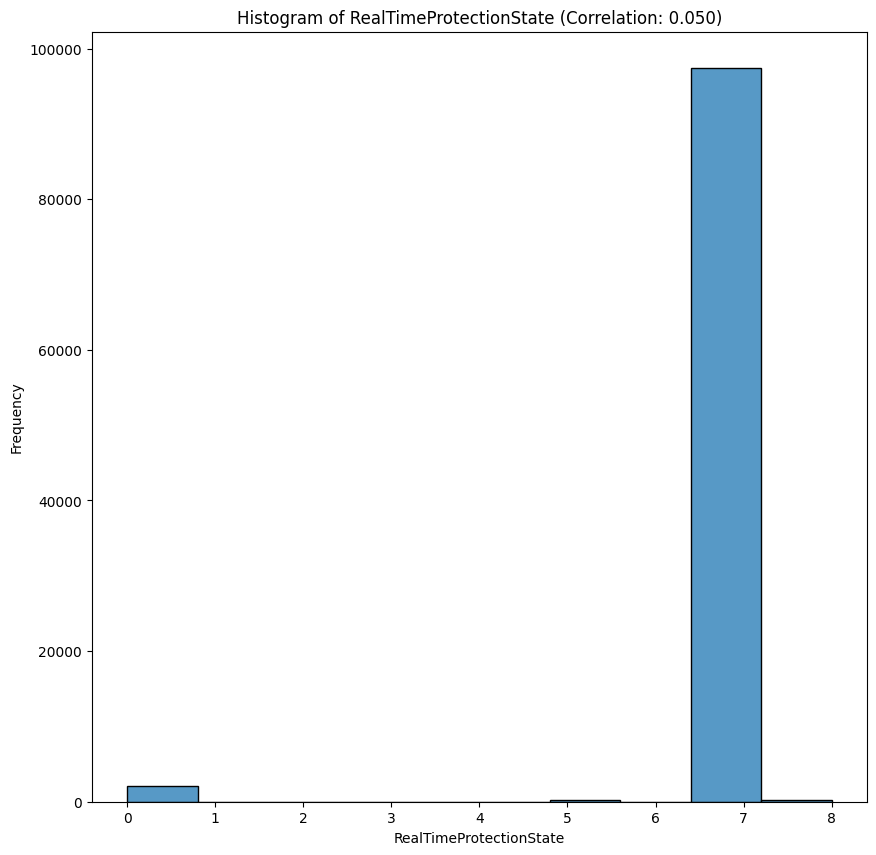

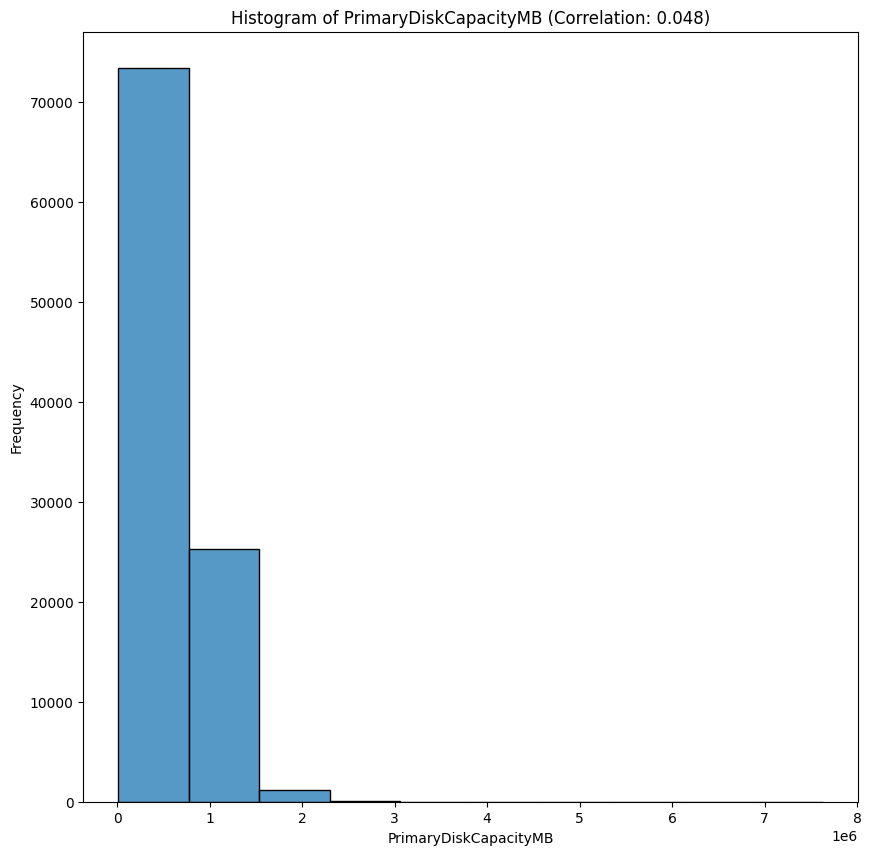

In [15]:
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)
    
    top_features = correlations.head(7).index.tolist()
    
    for feature in top_features:
        plt.figure(figsize=(10,10))
        sns.histplot(data[feature], bins=10)
        plt.title(f'Histogram of {feature} (Correlation: {correlations[feature]:.3f})')
        plt.xlabel(feature)
        plt.ylabel('Frequency')
        plt.show()

**Checking Duplicates**

In [16]:
data.duplicated().value_counts()

False    99833
True       167
Name: count, dtype: int64

**Checking for Null Values**

In [17]:
null_counts = data.isnull().sum()
null_columns = null_counts[null_counts > 0] # Identify columns that have null values

if not null_columns.empty:
    print("Columns with null values:") # Print the names of columns with null values and their corresponding counts
    print(null_columns)
else:
    print("No columns with null values found.") # If no columns have null values, print a message

Columns with null values:
RealTimeProtectionState                66
AntivirusConfigID                      76
NumAntivirusProductsInstalled          76
NumAntivirusProductsEnabled            76
CityID                                623
IsSystemProtected                      76
SMode                                 981
IEVersionID                           107
FirewallEnabled                       166
EnableLUA                              19
OEMNameID                             212
OEMModelID                            228
ProcessorCoreCount                     85
ProcessorManufacturerID                85
ProcessorModelID                       85
PrimaryDiskCapacityMB                 110
PrimaryDiskType                        23
SystemVolumeCapacityMB                110
TotalPhysicalRAMMB                    151
ChassisType                             2
PrimaryDisplayDiagonalInches           72
PrimaryDisplayResolutionHorizontal     72
PrimaryDisplayResolutionVertical       72
Internal

In [18]:
data["target"].value_counts()

target
1    50525
0    49475
Name: count, dtype: int64

**Distribution of Target Variable**

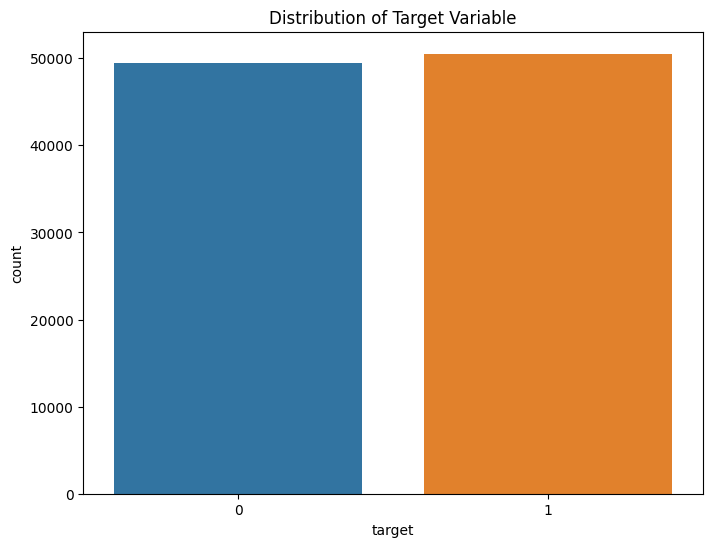

In [19]:
plt.figure(figsize=(8, 6))
sns.countplot(x='target', data=data)
plt.title('Distribution of Target Variable')
plt.show()

The count plot shows that the distribution of the target variable (0 and 1) is nearly balanced, indicating that the number of infected and uninfected systems is almost equal.

# Model-1

In [20]:
data = data.drop(columns=['MachineID'], errors='ignore') # Drop the 'MachineID' column if it exists, ignore errors if not found

X = data.drop("target", axis=1)
y = data["target"]

categorical_cols = X.select_dtypes(include=["object", "category"]).columns
numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="mean")), 
    ("scaler", StandardScaler())  
]) 

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")) 
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols)
    ])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

test_preprocessed = preprocessor.transform(test_data)

adaboost_model = AdaBoostClassifier(random_state=42)
adaboost_model.fit(X_train, y_train)

y_pred_adaboost = adaboost_model.predict(X_test) #Predict on test data and evaluate performance
print(" Validation Accuracy:", accuracy_score(y_test, y_pred_adaboost))
print("Classification Report:\n", classification_report(y_test, y_pred_adaboost))

y_pred_test = adaboost_model.predict(test_preprocessed) #Predict target values for final test data

submission = pd.DataFrame({"id": range(0,test_data.shape[0]), 
                           "target": y_pred_test}) # Create submission file

submission.to_csv('submission.csv',index=False)

 Validation Accuracy: 0.61395
Classification Report:
               precision    recall  f1-score   support

           0       0.63      0.55      0.58      9878
           1       0.61      0.68      0.64     10122

    accuracy                           0.61     20000
   macro avg       0.62      0.61      0.61     20000
weighted avg       0.62      0.61      0.61     20000



The AdaBoost model achieved an accuracy of 61.26% on the test dataset, demonstrating moderate predictive capability.

# Model 2

In [21]:
data = data.drop(columns=['MachineID'], errors='ignore')

X = data.drop("target", axis=1)
y = data["target"]

categorical_cols = X.select_dtypes(include=["object", "category"]).columns
numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="mean")), 
    ("scaler", StandardScaler())  
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")), 
    ("onehot", OneHotEncoder(handle_unknown="ignore"))  
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols)
    ])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)


# Define individual models
model1 = LogisticRegression(max_iter=5000, solver='saga', C=0.1, penalty='l2', random_state=42)
model2 = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
model3 = XGBClassifier(n_estimators=100, max_depth=5, random_state=42)

# Create a voting classifier combining all models
voting_model = VotingClassifier(
    estimators=[
        ('lr', model1),
        ('rf', model2),
        ('xgb', model3)
    ],
    voting='hard' 
)


voting_model.fit(X_train, y_train)

val_pred = voting_model.predict(X_test)
val_accuracy = accuracy_score(y_test, val_pred)
print(f"Validation Accuracy: {val_accuracy:.2f}")
print("Classification Report:\n", classification_report(y_test, val_pred))

# Perform 5-fold cross-validation
cv_scores = cross_val_score(voting_model, X_train, y_train, cv=5, scoring='accuracy')
print(f"Cross-validation Accuracy: {np.mean(cv_scores):.2f} ± {np.std(cv_scores):.2f}")

test_data = test_data.drop(columns=['MachineID'], errors='ignore')

test_preprocessed = preprocessor.transform(test_data)

test_pred = voting_model.predict(test_preprocessed)

submission = pd.DataFrame({"id": range(0,test_data.shape[0]), 
                           "target": test_pred}) 

submission.to_csv('submission.csv',index=False)

print("Predictions saved to 'submission.csv'.")


Validation Accuracy: 0.62
Classification Report:
               precision    recall  f1-score   support

           0       0.63      0.55      0.59      9878
           1       0.61      0.69      0.65     10122

    accuracy                           0.62     20000
   macro avg       0.62      0.62      0.62     20000
weighted avg       0.62      0.62      0.62     20000

Cross-validation Accuracy: 0.62 ± 0.00
Predictions saved to 'submission.csv'.


# Model 3

In [22]:
data = data.drop(columns=['MachineID'], errors='ignore')
test_data = test_data.drop(columns=['MachineID'], errors='ignore')

X = data.drop("target", axis=1)
y = data["target"]


categorical_cols = X.select_dtypes(include=["object", "category"]).columns
numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns


num_imputer = SimpleImputer(strategy="mean")
X[numerical_cols] = num_imputer.fit_transform(X[numerical_cols])
test_data[numerical_cols] = num_imputer.transform(test_data[numerical_cols])

cat_imputer = SimpleImputer(strategy="most_frequent")
X[categorical_cols] = cat_imputer.fit_transform(X[categorical_cols])
test_data[categorical_cols] = cat_imputer.transform(test_data[categorical_cols])

# Encode categorical columns using LabelEncoder
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])
    test_data[col] = test_data[col].apply(lambda x: le.transform([x])[0] if x in le.classes_ else -1)
    label_encoders[col] = le


scaler = StandardScaler()
X[numerical_cols] = scaler.fit_transform(X[numerical_cols])
test_data[numerical_cols] = scaler.transform(test_data[numerical_cols])

# Apply PCA to reduce dimensionality to 55 components
pca = PCA(n_components=55, random_state=42)
X_pca = pca.fit_transform(X)
test_pca = pca.transform(test_data)


X_train, X_test, y_train, y_test = train_test_split(X_pca, y, test_size=0.2, random_state=42)

# Train a Random Forest model
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
rf_model.fit(X_train, y_train)

y_test_pred = rf_model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Validation Accuracy: {test_accuracy:.2f}")
print("\n Classification Report:\n", classification_report(y_test, y_test_pred))


test_pred = rf_model.predict(test_pca)


submission = pd.DataFrame({
    "id": range(0, test_data.shape[0]), 
    "target": test_pred
})

submission.to_csv('submission.csv', index=False)
print("Predictions saved to 'submission.csv'.")


Validation Accuracy: 0.61

 Classification Report:
               precision    recall  f1-score   support

           0       0.63      0.53      0.57      9878
           1       0.60      0.70      0.65     10122

    accuracy                           0.61     20000
   macro avg       0.61      0.61      0.61     20000
weighted avg       0.61      0.61      0.61     20000

Predictions saved to 'submission.csv'.


# Model 4

In [23]:
data = data.drop(columns=['MachineID'], errors='ignore')
test_data = test_data.drop(columns=['MachineID'], errors='ignore')

X = data.drop("target", axis=1)
y = data["target"]

categorical_cols = X.select_dtypes(include=["object", "category"]).columns
numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns

num_imputer = SimpleImputer(strategy="mean")
X[numerical_cols] = num_imputer.fit_transform(X[numerical_cols])
test_data[numerical_cols] = num_imputer.transform(test_data[numerical_cols])

cat_imputer = SimpleImputer(strategy="most_frequent")
X[categorical_cols] = cat_imputer.fit_transform(X[categorical_cols])
test_data[categorical_cols] = cat_imputer.transform(test_data[categorical_cols])

# Apply Ordinal Encoding to Categorical Variables
ord_encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
X[categorical_cols] = ord_encoder.fit_transform(X[categorical_cols])
test_data[categorical_cols] = ord_encoder.transform(test_data[categorical_cols])

scaler = StandardScaler()
X[numerical_cols] = scaler.fit_transform(X[numerical_cols])
test_data[numerical_cols] = scaler.transform(test_data[numerical_cols])

# Define base XGBoost model
xgb_base = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42, eval_metric='mlogloss')

# Apply RFE to Select 45 Best Features
rfe = RFE(estimator=xgb_base, n_features_to_select=45, step=5)
X_selected = rfe.fit_transform(X, y)
test_data_selected = rfe.transform(test_data)

X_train, X_test, y_train, y_test = train_test_split(X_selected, y, test_size=0.2, random_state=42)

# Initial Model Training (Without Hyperparameter Tuning)
print("Training Initial XGBoost Model...")
xgb_base.fit(X_train, y_train)
y_pred_initial = xgb_base.predict(X_test)

print("Validation Accuracy:", accuracy_score(y_test, y_pred_initial))
print("\nClassification Report:\n", classification_report(y_test, y_pred_initial))

# Define Hyperparameter Grid for Randomized Search
param_grid = {
    'n_estimators': [100, 200, 300, 500],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 5, 7, 10],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.5, 0.7, 0.9, 1.0]
}

# Hyperparameter Tuning with Randomized Search
print("\nStarting Hyperparameter Tuning with Randomized Search...")
xgb_model = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='mlogloss')

random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_grid,
    n_iter=10,  # Number of random combinations to try
    scoring="accuracy",
    cv=5,
    verbose=2,
    n_jobs=-1,
    random_state=42
)

# Fit Randomized Search
random_search.fit(X_train, y_train)

# Best Model from Random Search
best_xgb_model = random_search.best_estimator_

y_pred_tuned = best_xgb_model.predict(X_test)
print("\nBest Model Accuracy After Tuning:", accuracy_score(y_test, y_pred_tuned))
print(classification_report(y_test, y_pred_tuned))

test_pred = best_xgb_model.predict(test_data_selected)

submission = pd.DataFrame({
    "id": range(0, test_data.shape[0]),
    "target": test_pred
})

submission.to_csv('submission.csv', index=False)
print("Predictions saved to 'submission.csv'.")


Training Initial XGBoost Model...
Validation Accuracy: 0.62845

Classification Report:
               precision    recall  f1-score   support

           0       0.64      0.57      0.60      9878
           1       0.62      0.69      0.65     10122

    accuracy                           0.63     20000
   macro avg       0.63      0.63      0.63     20000
weighted avg       0.63      0.63      0.63     20000


Starting Hyperparameter Tuning with Randomized Search...
Fitting 5 folds for each of 10 candidates, totalling 50 fits

Best Model Accuracy After Tuning: 0.63245
              precision    recall  f1-score   support

           0       0.64      0.58      0.61      9878
           1       0.63      0.68      0.65     10122

    accuracy                           0.63     20000
   macro avg       0.63      0.63      0.63     20000
weighted avg       0.63      0.63      0.63     20000

Predictions saved to 'submission.csv'.
